In [1]:
# 1. Libraries
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
# 2. Folders and image filenames
input_folder = Path("raw/MCP")
output_folder = Path("output/mcp")
radial_folder = output_folder / "radial"
filenames = [
    "26-11-09_00006_TDC_2D_chopper1_Zone01.txt",
    # "26-11-09_00006_TDC_2D_chopper1_Zone02.txt",
    # Add more filenames here to compare.
]
output_folder.mkdir(parents=True, exist_ok=True)
radial_folder.mkdir(parents=True, exist_ok=True)

In [3]:
# 3. Load detector images
images = [np.loadtxt(input_folder / name) for name in filenames]
height, width = images[0].shape
for name, image in zip(filenames, images):
    print(name, image.shape, "total counts:", np.nansum(image))

26-11-09_00006_TDC_2D_chopper1_Zone01.txt (2000, 2400) total counts: 125831.0


In [4]:
# 4. Center, radial bins, display, and optional painted mask
center_x = (width - 1) / 2        # column; adjust to your beam center
center_y = (height - 1) / 2       # row
radial_bin_width = 10.0          # original pixels
radial_max = max(np.hypot(x - center_x, y - center_y)
                 for x in (0, width - 1) for y in (0, height - 1)) + 1
circle_radii = [300, 600, 900]    # center-finding guides; [] disables
mask_path = None                 # e.g. output_folder / "beamstop_mask.png"

# Display only: average small blocks so sparse counts are visible.
display_bin_size = 10            # must divide both image dimensions; 1 = original
upper_percentile = 99.5          # positive displayed intensities outside mask
mi, ma = 0, None                 # None for ma selects the percentile limit
mask = np.zeros((height, width), dtype=bool)
if mask_path is not None:
    with Image.open(mask_path) as file:
        rgba = np.asarray(file.convert("RGBA"))
    mask = np.flipud((rgba[..., 0] >= 200) & (rgba[..., 1] < 100) &
                     (rgba[..., 2] < 100) & (rgba[..., 3] > 0))

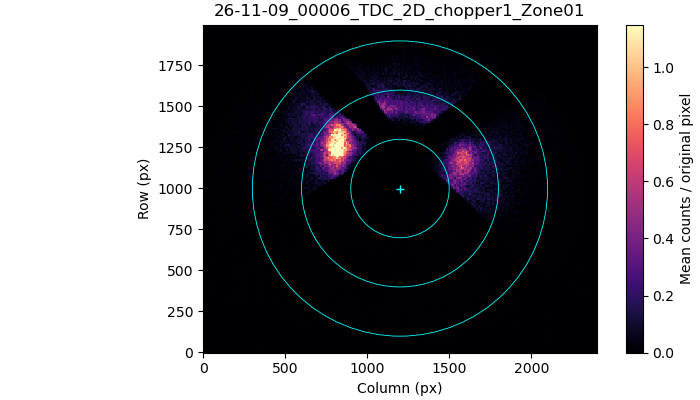

In [5]:
# 5. Show each image (7 x 4), always with a colorbar
image_figures = []
b = display_bin_size
for name, image in zip(filenames, images):
    valid = np.isfinite(image) & ~mask
    total = np.where(valid, image, 0).reshape(height // b, b, width // b, b).sum(axis=(1, 3))
    count = valid.reshape(height // b, b, width // b, b).sum(axis=(1, 3))
    shown = np.full(total.shape, np.nan)
    np.divide(total, count, out=shown, where=count > 0)
    positive = shown[np.isfinite(shown) & (shown > 0)]
    vmax = ma if ma is not None else (np.percentile(positive, upper_percentile) if positive.size else mi + 1)
    vmax = max(vmax, mi + 1e-12)
    fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    artist = ax.imshow(shown, origin="lower", cmap="magma", vmin=mi, vmax=vmax,
                       extent=(-0.5, width - 0.5, -0.5, height - 0.5), interpolation="nearest")
    ax.plot(center_x, center_y, "+", color="cyan")
    for r in circle_radii:
        ax.add_patch(plt.Circle((center_x, center_y), r, fill=False, color="cyan", linewidth=0.6))
    ax.set_xlim(-0.5, width - 0.5)
    ax.set_ylim(-0.5, height - 0.5)
    ax.set(title=Path(name).stem, xlabel="Column (px)", ylabel="Row (px)")
    fig.colorbar(artist, ax=ax, label="Mean counts / original pixel")
    image_figures.append(fig)
    plt.show()

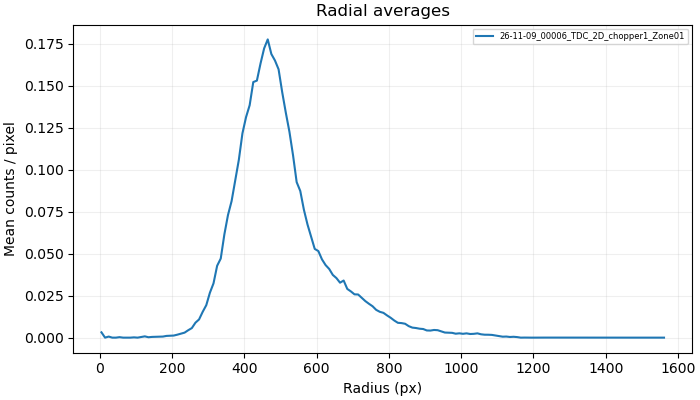

In [6]:
# 6. Radial averages from ORIGINAL pixels, excluding masked/non-finite pixels
# Zeros are valid; empty bins stay NaN. Units are pixels (no q calibration).
y, x = np.indices((height, width))
radius = np.hypot(x - center_x, y - center_y)
edges = np.append(np.arange(0, radial_max, radial_bin_width), radial_max)
radii = (edges[:-1] + edges[1:]) / 2
radial_profiles, radial_pixel_counts, radial_sums = [], [], []
for image in images:
    valid = np.isfinite(image) & ~mask & (radius <= radial_max)
    count = np.histogram(radius[valid], bins=edges)[0]
    total = np.histogram(radius[valid], bins=edges, weights=image[valid])[0]
    profile = np.full(len(radii), np.nan)
    np.divide(total, count, out=profile, where=count > 0)
    radial_profiles.append(profile)
    radial_pixel_counts.append(count)
    radial_sums.append(total)
radial_figure, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for name, profile in zip(filenames, radial_profiles):
    ax.plot(radii, profile, label=Path(name).stem)
ax.set(xlabel="Radius (px)", ylabel="Mean counts / pixel", title="Radial averages")
ax.legend(fontsize=6)
ax.grid(alpha=0.2)
plt.show()

In [7]:
# 7. Save images as plotted, the radial plot, and numerical radial data
for name, fig, profile, count, total in zip(filenames, image_figures, radial_profiles,
                                           radial_pixel_counts, radial_sums):
    stem = Path(name).stem
    fig.savefig(output_folder / f"{stem}_image.png", dpi=160)
    np.savetxt(radial_folder / f"{stem}_radial.csv",
               np.c_[radii, profile, total, count], delimiter=",", comments="",
               header="radius_px,mean_counts_per_pixel,sum_counts,valid_pixels")
    np.savez(radial_folder / f"{stem}_radial.npz", radius_px=radii,
             radial_edges=edges, radial_average=profile, sum_counts=total, valid_pixels=count,
             center_xy=[center_x, center_y], mask=mask)
radial_figure.savefig(output_folder / "mcp_radial_comparison.png", dpi=160)
print("Images and plots:", output_folder.resolve())
print("Radial data:", radial_folder.resolve())

Images and plots: /Users/riccardo/Github/SEXTANTS_261105/output/mcp
Radial data: /Users/riccardo/Github/SEXTANTS_261105/output/mcp/radial
